In [5]:
import os

# ── PH2 Dataset ─────────────────────────────────────────────
DATASET_ROOT = "/kaggle/input/datasets/hashbanger/isic2017-and-ph2/ISIC_2017 + PH2/PH2"

FRAMES_PATH = os.path.join(DATASET_ROOT, "trainx")
MASKS_PATH  = os.path.join(DATASET_ROOT, "trainy")

print(f"Images path exists : {os.path.exists(FRAMES_PATH)}")
print(f"Masks  path exists : {os.path.exists(MASKS_PATH)}")

# ── Collect image-mask pairs ────────────────────────────────
frame_files = []
mask_files = []

all_imgs = sorted([
    f for f in os.listdir(FRAMES_PATH)
    if f.lower().endswith(".bmp")
])

for img_name in all_imgs:
    # Remove .bmp extension
    base_name = os.path.splitext(img_name)[0]

    # Expected mask name
    mask_name = f"{base_name}_lesion.bmp"

    img_path = os.path.join(FRAMES_PATH, img_name)
    mask_path = os.path.join(MASKS_PATH, mask_name)

    if os.path.exists(mask_path):
        frame_files.append(img_path)
        mask_files.append(mask_path)
    else:
        print(f"Missing mask: {mask_name}")

print(f"\nMatched image-mask pairs : {len(frame_files)}")
print(f"First 5 images : {[os.path.basename(p) for p in frame_files[:5]]}")
print(f"First 5 masks  : {[os.path.basename(p) for p in mask_files[:5]]}")

Images path exists : True
Masks  path exists : True

Matched image-mask pairs : 200
First 5 images : ['IMD002.bmp', 'IMD003.bmp', 'IMD004.bmp', 'IMD006.bmp', 'IMD008.bmp']
First 5 masks  : ['IMD002_lesion.bmp', 'IMD003_lesion.bmp', 'IMD004_lesion.bmp', 'IMD006_lesion.bmp', 'IMD008_lesion.bmp']


# **Import necessary libraries**

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os
import gc
import random
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split

# ── Memory fix: allow GPU memory to grow incrementally ──
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

print("GPU Available: ", tf.config.list_physical_devices('GPU'))
print("TensorFlow version:", tf.__version__)


2026-06-09 10:33:08.613683: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781001188.787830      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781001188.837282      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781001189.217429      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781001189.217467      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781001189.217470      58 computation_placer.cc:177] computation placer alr

GPU Available:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow version: 2.19.0


# **Set data paths and verify dataset**

In [7]:
import matplotlib.pyplot as plt
import random

print(f"Total matched pairs   : {len(frame_files)}")
print(f"Images directory      : {FRAMES_PATH}")
print(f"Masks  directory      : {MASKS_PATH}")

# Quick size sanity check on first image
import cv2
sample_img  = cv2.imread(os.path.join(FRAMES_PATH, frame_files[0]))
sample_mask = cv2.imread(os.path.join(MASKS_PATH,  mask_files[0]), cv2.IMREAD_GRAYSCALE)
print(f"\nSample image shape : {sample_img.shape}")
print(f"Sample mask  shape : {sample_mask.shape}")
print(f"Mask unique values : {sorted(set(sample_mask.flatten().tolist()[:100]))}")


Total matched pairs   : 200
Images directory      : /kaggle/input/datasets/hashbanger/isic2017-and-ph2/ISIC_2017 + PH2/PH2/trainx
Masks  directory      : /kaggle/input/datasets/hashbanger/isic2017-and-ph2/ISIC_2017 + PH2/PH2/trainy

Sample image shape : (572, 765, 3)
Sample mask  shape : (572, 765)
Mask unique values : [0]


# **PH2 Dataset Analysis & Sample Distribution**


Total matched pairs: 200

Sample size             : 200
Foreground ratio — mean : 0.322
Foreground ratio — std  : 0.234
Image height range      : 553–577 px
Image width  range      : 761–769 px


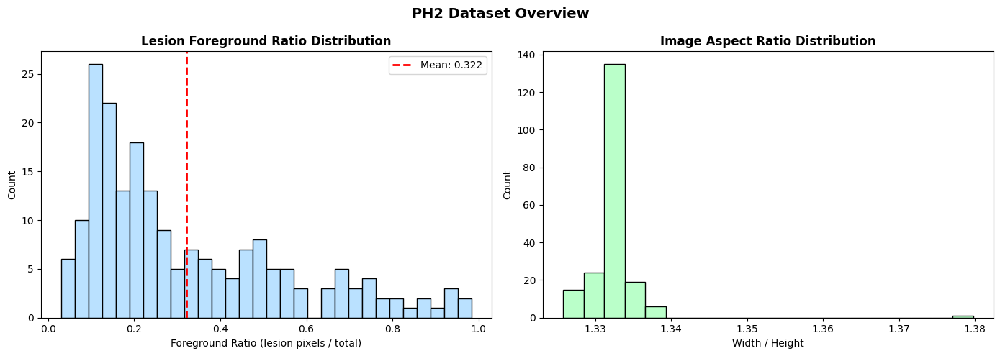

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import cv2, os, random

print(f"Total matched pairs: {len(frame_files)}")

# Compute mask coverage (foreground ratio) for a sample
sample_size = min(200, len(frame_files))
sample_idx  = random.sample(range(len(frame_files)), sample_size)

fg_ratios = []
heights, widths = [], []

for idx in sample_idx:
    mask = cv2.imread(mask_files[idx], cv2.IMREAD_GRAYSCALE)
    img  = cv2.imread(frame_files[idx])
    if mask is None or img is None:
        continue
    fg_ratios.append(np.mean(mask > 127))
    heights.append(img.shape[0])
    widths.append(img.shape[1])

fg_ratios = np.array(fg_ratios)
print(f"\nSample size             : {len(fg_ratios)}")
print(f"Foreground ratio — mean : {fg_ratios.mean():.3f}")
print(f"Foreground ratio — std  : {fg_ratios.std():.3f}")
print(f"Image height range      : {min(heights)}–{max(heights)} px")
print(f"Image width  range      : {min(widths)}–{max(widths)} px")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(fg_ratios, bins=30, color='#bae1ff', edgecolor='black')
axes[0].axvline(fg_ratios.mean(), color='red', linestyle='--', linewidth=2,
                label=f'Mean: {fg_ratios.mean():.3f}')
axes[0].set_title('Lesion Foreground Ratio Distribution', fontweight='bold')
axes[0].set_xlabel('Foreground Ratio (lesion pixels / total)')
axes[0].set_ylabel('Count')
axes[0].legend()

aspects = [w/h for h, w in zip(heights, widths)]
axes[1].hist(aspects, bins=20, color='#baffc9', edgecolor='black')
axes[1].set_title('Image Aspect Ratio Distribution', fontweight='bold')
axes[1].set_xlabel('Width / Height')
axes[1].set_ylabel('Count')

plt.suptitle('PH2 Dataset Overview', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# **Visualize random samples from dataset**

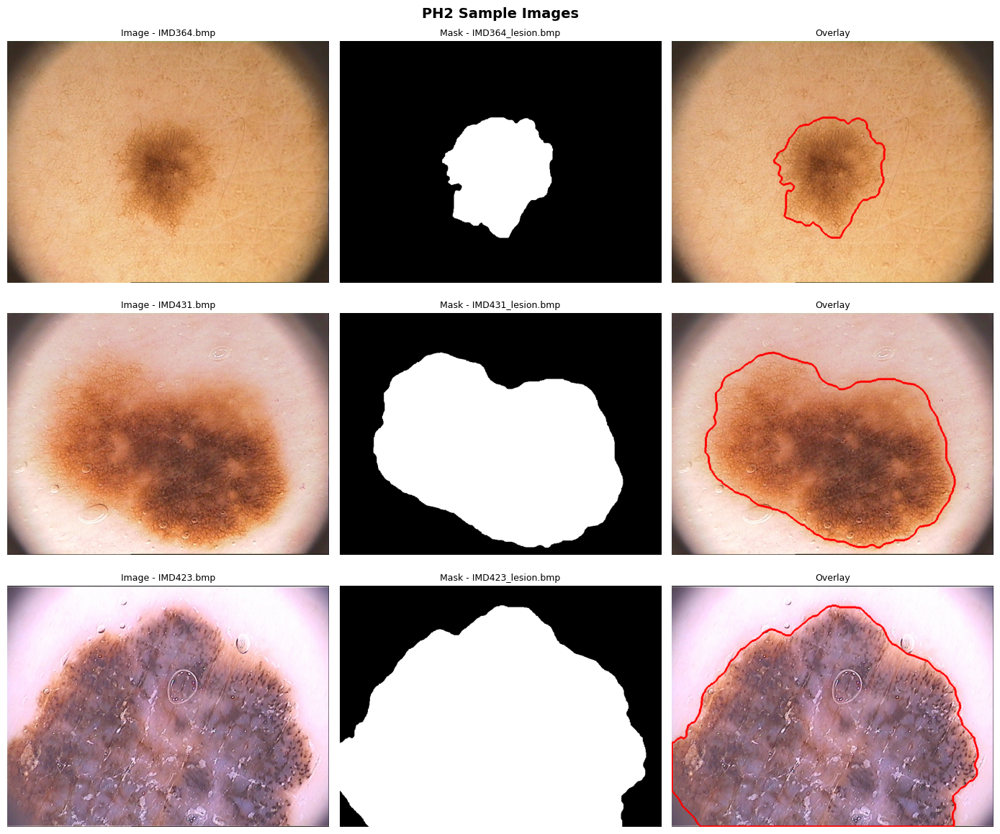

In [9]:
def visualize_samples(num_samples=3):
    """Display random image/mask pairs from PH2"""

    fig, axes = plt.subplots(num_samples, 3, figsize=(14, num_samples * 4))

    random_indices = random.sample(range(len(frame_files)), num_samples)

    for idx, rand_idx in enumerate(random_indices):

        img_path  = frame_files[rand_idx]
        mask_path = mask_files[rand_idx]

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Overlay
        overlay = image.copy()
        contours, _ = cv2.findContours((mask > 127).astype(np.uint8),
                                        cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(overlay, contours, -1, (255, 0, 0), 3)

        axes[idx, 0].imshow(image)
        axes[idx, 0].set_title(f'Image - {os.path.basename(img_path)}', fontsize=9)
        axes[idx, 0].axis('off')

        axes[idx, 1].imshow(mask, cmap='gray')
        axes[idx, 1].set_title(f'Mask - {os.path.basename(mask_path)}', fontsize=9)
        axes[idx, 1].axis('off')

        axes[idx, 2].imshow(overlay)
        axes[idx, 2].set_title('Overlay', fontsize=9)
        axes[idx, 2].axis('off')

    plt.suptitle('PH2 Sample Images', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


visualize_samples(3)


# **Set configuration and hyperparameters**

In [12]:
CONFIG = {
    'IMG_HEIGHT': 224,       # reduced from 256 — saves ~23 % memory per image
    'IMG_WIDTH': 224,
    'IMG_CHANNELS': 3,
    'BATCH_SIZE': 8,         # reduced from 16 — halves GPU/CPU batch memory
    'EPOCHS': 150,
    'LEARNING_RATE': 1e-4,
    'VALIDATION_SPLIT': 0.15,
    'TEST_SPLIT': 0.15,
    'EARLY_STOPPING_PATIENCE': 3,
    'REDUCE_LR_PATIENCE': 40,
    'DROPOUT_RATE': 0.3,
    'L2_REG': 1e-4,
    'LABEL_SMOOTHING': 0.05,
}

print("Configuration:")
for key, value in CONFIG.items():
    print(f"{key}: {value}")


Configuration:
IMG_HEIGHT: 224
IMG_WIDTH: 224
IMG_CHANNELS: 3
BATCH_SIZE: 8
EPOCHS: 150
LEARNING_RATE: 0.0001
VALIDATION_SPLIT: 0.15
TEST_SPLIT: 0.15
EARLY_STOPPING_PATIENCE: 3
REDUCE_LR_PATIENCE: 40
DROPOUT_RATE: 0.3
L2_REG: 0.0001
LABEL_SMOOTHING: 0.05


# **Create data loading and preprocessing functions**

# **PH2-Specific Preprocessing**

Three key steps before model input:
1. **Hair removal** – blackhat morphology + inpainting removes hair artefacts (dermoscopy images)
2. **Color constancy** – Shades-of-Gray normalization corrects dermoscope lighting
3. **Standardized resize & normalize** for MobileNetV2 ImageNet weights


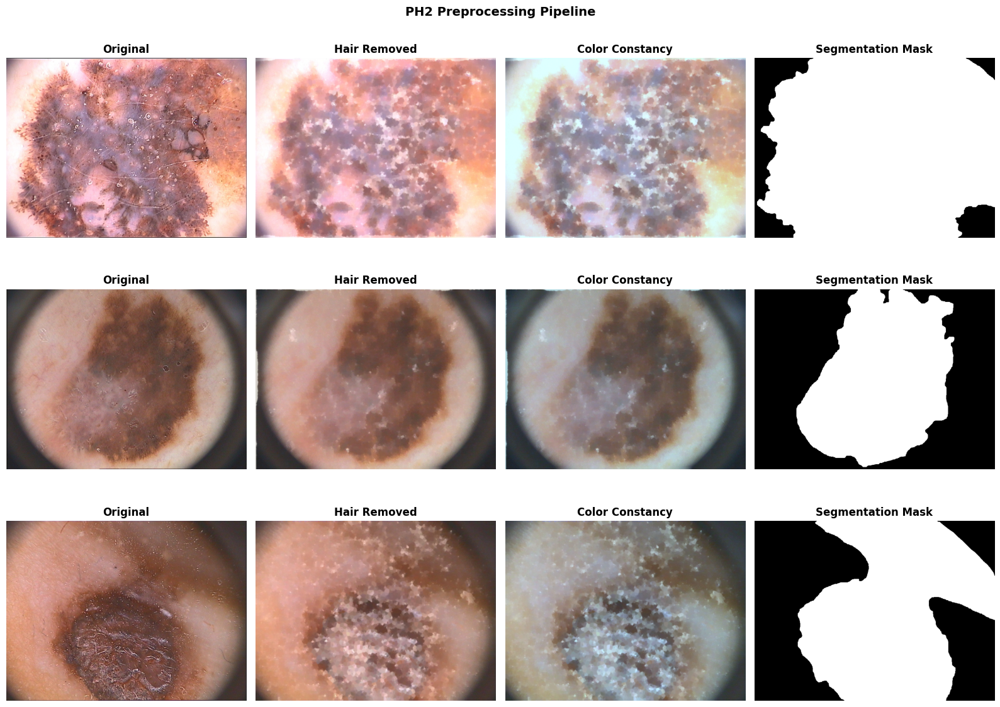

In [13]:
import cv2
import numpy as np


# ─────────────────────────────────────────────
# 1. HAIR REMOVAL
#    Blackhat morphology highlights dark thin
#    structures (hairs). Threshold + inpaint
#    fills them with surrounding skin texture.
# ─────────────────────────────────────────────
def remove_hair(image: np.ndarray,
                kernel_size: int = 17,
                threshold: int = 10) -> np.ndarray:
    """
    Remove hair artefacts from a dermoscopic image (uint8 RGB).

    Parameters
    ----------
    image       : H×W×3 uint8 RGB image
    kernel_size : blackhat kernel size (odd number; larger = catches thicker hairs)
    threshold   : binarisation threshold on the blackhat result

    Returns
    -------
    inpainted H×W×3 uint8 RGB image
    """
    gray   = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT,
                                       (kernel_size, kernel_size))
    # Blackhat highlights dark structures on a bright background
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)

    # Threshold to get binary hair mask
    _, hair_mask = cv2.threshold(blackhat, threshold, 255, cv2.THRESH_BINARY)

    # Inpaint removes hair and fills with local neighbourhood
    inpainted = cv2.inpaint(image, hair_mask,
                            inpaintRadius=3,
                            flags=cv2.INPAINT_TELEA)
    return inpainted


# ─────────────────────────────────────────────
# 2. COLOR CONSTANCY (Shades of Gray)
#    Corrects for dermoscope light source colour
#    differences so the model sees consistent hues.
# ─────────────────────────────────────────────
def shades_of_gray(image: np.ndarray, power: int = 6) -> np.ndarray:
    """
    Shades-of-Gray colour constancy (Finlayson & Trezzi, 2004).

    Parameters
    ----------
    image : H×W×3 uint8 RGB image
    power : Minkowski norm order (6 works well for skin lesions)

    Returns
    -------
    Colour-corrected H×W×3 uint8 image
    """
    img_float = image.astype(np.float32) + 1e-6

    # Per-channel Minkowski norm
    norm = np.power(
        np.mean(np.power(img_float, power), axis=(0, 1)),
        1.0 / power
    )

    # Scale so overall illuminant is grey
    scale = (norm / (np.mean(norm) + 1e-6))
    corrected = img_float / scale

    corrected = np.clip(corrected, 0, 255).astype(np.uint8)
    return corrected


# ─────────────────────────────────────────────
# 3. COMBINED PREPROCESSING PIPELINE
# ─────────────────────────────────────────────
def preprocess_ph2(image_rgb: np.ndarray) -> np.ndarray:
    """
    Full PH2 preprocessing pipeline.
    Input  : H×W×3 uint8 RGB
    Output : H×W×3 uint8 RGB  (ready for resize + normalisation)
    """
    # Step 1: Remove hair artefacts
    image_rgb = remove_hair(image_rgb, kernel_size=17, threshold=10)

    # Step 2: Colour constancy
    image_rgb = shades_of_gray(image_rgb, power=6)

    return image_rgb


# ─────────────────────────────────────────────
# Quick visual check of the pipeline
# ─────────────────────────────────────────────
def visualize_preprocessing_steps(num_samples: int = 3) -> None:

    fig, axes = plt.subplots(num_samples, 4,
                             figsize=(16, num_samples * 4))

    sample_idx = random.sample(range(len(frame_files)), num_samples)

    for row, idx in enumerate(sample_idx):

        raw = cv2.imread(frame_files[idx])
        raw = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)

        hair_removed  = remove_hair(raw)
        color_correct = shades_of_gray(hair_removed)
        mask_img      = cv2.imread(mask_files[idx],
                                   cv2.IMREAD_GRAYSCALE)

        for col, (img, title) in enumerate([
            (raw,           'Original'),
            (hair_removed,  'Hair Removed'),
            (color_correct, 'Color Constancy'),
            (mask_img,      'Segmentation Mask'),
        ]):
            if col < 3:
                axes[row, col].imshow(img)
            else:
                axes[row, col].imshow(img, cmap='gray')
            axes[row, col].set_title(title, fontweight='bold')
            axes[row, col].axis('off')

    plt.suptitle('PH2 Preprocessing Pipeline', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


visualize_preprocessing_steps(3)


In [14]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess


def load_and_preprocess_image(image_path, mask_path, img_height, img_width):
    """
    Load, preprocess and return an (image, mask) pair for PH2.
    """
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image = remove_hair(image, kernel_size=17, threshold=10)
    image = shades_of_gray(image, power=6)

    image = cv2.resize(image, (img_width, img_height))
    image = mobilenet_preprocess(image.astype(np.float32))

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (img_width, img_height),
                      interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)

    return image, mask


def load_dataset(image_files, mask_files, images_path, masks_path,
                 img_height, img_width):
    """
    Load dataset in small chunks to avoid OOM.
    Uses float32 and clears memory after each chunk.
    """
    CHUNK = 500   # process 500 images at a time
    images_list, masks_list = [], []

    print("Loading & preprocessing PH2 dataset (chunked)...")

    for start in range(0, len(image_files), CHUNK):
        chunk_imgs  = image_files[start:start + CHUNK]
        chunk_masks = mask_files [start:start + CHUNK]

        chunk_X, chunk_y = [], []

        for img_file, mask_file in tqdm(zip(chunk_imgs, chunk_masks),
                                         total=len(chunk_imgs),
                                         desc=f"Chunk {start//CHUNK + 1}"):
            # PH2: frame_files/mask_files already contain full paths
            ip = img_file
            mp = mask_file
            image, mask = load_and_preprocess_image(ip, mp, img_height, img_width)
            chunk_X.append(image)
            chunk_y.append(mask)

        images_list.append(np.array(chunk_X, dtype=np.float32))
        masks_list .append(np.array(chunk_y, dtype=np.float32))

        del chunk_X, chunk_y
        gc.collect()

    images = np.concatenate(images_list, axis=0)
    masks  = np.concatenate(masks_list,  axis=0)

    del images_list, masks_list
    gc.collect()

    return images, masks


X, y = load_dataset(
    frame_files, mask_files,
    FRAMES_PATH, MASKS_PATH,
    CONFIG['IMG_HEIGHT'], CONFIG['IMG_WIDTH']
)

print("\nDataset loaded successfully!")
print(f"Images shape : {X.shape}")
print(f"Masks  shape : {y.shape}")
print(f"Images range : [{X.min():.3f}, {X.max():.3f}]   (MobileNetV2 normalised)")
print(f"Masks  range : [{y.min():.3f}, {y.max():.3f}]")


Loading & preprocessing PH2 dataset (chunked)...


Chunk 1: 100%|██████████| 200/200 [01:03<00:00,  3.17it/s]



Dataset loaded successfully!
Images shape : (200, 224, 224, 3)
Masks  shape : (200, 224, 224, 1)
Images range : [-0.992, 1.000]   (MobileNetV2 normalised)
Masks  range : [0.000, 1.000]


# **Split data into train, validation, and test sets**

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

Data split completed:
Training set   : 139 samples
Validation set : 31 samples
Test set       : 30 samples

Total: 200 samples


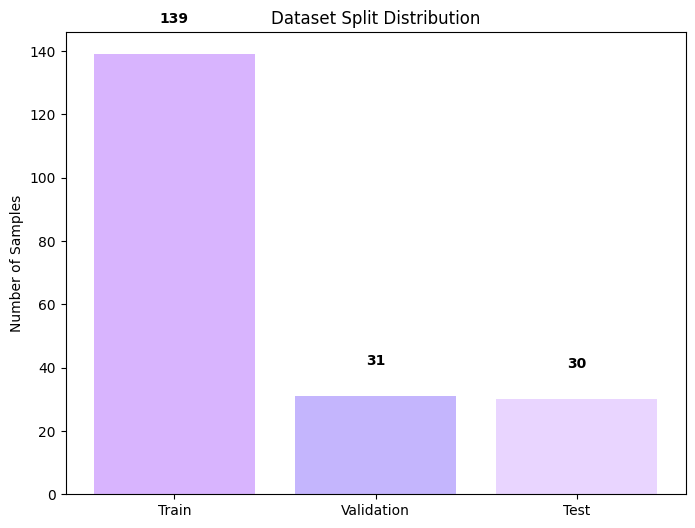

In [16]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=CONFIG['TEST_SPLIT'],
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=CONFIG['VALIDATION_SPLIT'] / (1 - CONFIG['TEST_SPLIT']),
    random_state=42
)

# ── Memory fix: free the unsplit arrays immediately ──
del X, y, X_temp, y_temp
gc.collect()

print("Data split completed:")
print(f"Training set   : {X_train.shape[0]} samples")
print(f"Validation set : {X_val.shape[0]} samples")
print(f"Test set       : {X_test.shape[0]} samples")
print(f"\nTotal: {X_train.shape[0] + X_val.shape[0] + X_test.shape[0]} samples")

plt.figure(figsize=(8, 6))
splits = ['Train', 'Validation', 'Test']
counts = [X_train.shape[0], X_val.shape[0], X_test.shape[0]]
colors = ['#d8b4fe', '#c4b5fd', '#e9d5ff']
plt.bar(splits, counts, color=colors, linewidth=1.5)
plt.ylabel('Number of Samples')
plt.title('Dataset Split Distribution')
for i, v in enumerate(counts):
    plt.text(i, v + 10, str(v), ha='center', fontweight='bold')
plt.show()


# **SENet_MobileNetV2_Mini_Swin_UNet**

In [17]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2


# ============================================================
# SE BLOCK
# ============================================================
def se_block(input_tensor, ratio=16):
    channels = input_tensor.shape[-1]

    se = layers.GlobalAveragePooling2D()(input_tensor)
    se = layers.Dense(max(channels // ratio, 4), activation='relu')(se)
    se = layers.Dense(channels, activation='sigmoid')(se)
    se = layers.Reshape((1, 1, channels))(se)

    return layers.Multiply()([input_tensor, se])


# ============================================================
# RESIZE UTILITY
# ============================================================
def resize_to_match(x, ref):
    return layers.Lambda(
        lambda t: tf.image.resize(t[0], tf.shape(t[1])[1:3])
    )([x, ref])


# ============================================================
# MINI SWIN BLOCK (UNCHANGED)
# ============================================================
def mini_swin_block(x, num_heads=4, mlp_dim=256):
    shortcut = x
    c = x.shape[-1]

    x = layers.LayerNormalization()(x)

    attn = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=max(c // num_heads, 8)
    )(x, x)

    x = layers.Add()([shortcut, attn])

    mlp = layers.LayerNormalization()(x)
    mlp = layers.Dense(mlp_dim, activation='relu')(mlp)
    mlp = layers.Dense(c)(mlp)

    x = layers.Add()([x, mlp])

    return x


# ============================================================
# SWIN BOTTLENECK (LIGHTWEIGHT)
# ============================================================
def swin_bottleneck(x):

    x = layers.Conv2D(192, 1, padding='same', activation='relu')(x)

    shape = tf.keras.backend.int_shape(x)
    h, w, c = shape[1], shape[2], shape[3]

    x = layers.Reshape((h * w, c))(x)

    x = mini_swin_block(x)
    x = mini_swin_block(x)

    x = layers.Reshape((h, w, c))(x)

    x = layers.Conv2D(320, 1, padding='same', activation='relu')(x)

    return x


# ============================================================
# MODEL BUILDER (MobileNetV2 VERSION)
# ============================================================
def build_unet_mobilenetv2_swin_se(img_height, img_width, img_channels):

    inputs = layers.Input((img_height, img_width, img_channels))

    # Handle grayscale
    if img_channels == 1:
        x = layers.Concatenate()([inputs, inputs, inputs])
    else:
        x = inputs

    # ========================================================
    # MOBILE NET V2 ENCODER
    # ========================================================
    base_model = MobileNetV2(
        include_top=False,
        weights='imagenet',
        input_tensor=x
    )

    # Fine-tuning (lighter than DenseNet)
    for layer in base_model.layers[:-80]:
        layer.trainable = False
    for layer in base_model.layers[-80:]:
        layer.trainable = True

    # ========================================================
    # SKIP CONNECTIONS (MobileNetV2 specific)
    # ========================================================
    s1 = base_model.get_layer("block_1_expand_relu").output   # low-level edges
    s2 = base_model.get_layer("block_3_expand_relu").output
    s3 = base_model.get_layer("block_6_expand_relu").output
    s4 = base_model.get_layer("block_13_expand_relu").output

    b1 = base_model.output  # deepest feature map

    # ========================================================
    # SE ATTENTION
    # ========================================================
    s1 = se_block(s1)
    s2 = se_block(s2)
    s3 = se_block(s3)
    s4 = se_block(s4)
    b1 = se_block(b1)

    # ========================================================
    # SWIN BOTTLENECK
    # ========================================================
    b1 = swin_bottleneck(b1)

    # ========================================================
    # DECODER (lighter than DenseNet version)
    # ========================================================
    u1 = layers.Conv2DTranspose(320, 2, strides=2, padding='same')(b1)
    s4r = resize_to_match(s4, u1)
    u1 = layers.concatenate([u1, s4r])
    c1 = se_block(layers.Conv2D(320, 3, activation='relu', padding='same')(u1))

    u2 = layers.Conv2DTranspose(192, 2, strides=2, padding='same')(c1)
    s3r = resize_to_match(s3, u2)
    u2 = layers.concatenate([u2, s3r])
    c2 = se_block(layers.Conv2D(192, 3, activation='relu', padding='same')(u2))

    u3 = layers.Conv2DTranspose(96, 2, strides=2, padding='same')(c2)
    s2r = resize_to_match(s2, u3)
    u3 = layers.concatenate([u3, s2r])
    c3 = se_block(layers.Conv2D(96, 3, activation='relu', padding='same')(u3))

    u4 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c3)
    s1r = resize_to_match(s1, u4)
    u4 = layers.concatenate([u4, s1r])
    c4 = se_block(layers.Conv2D(64, 3, activation='relu', padding='same')(u4))

    # ========================================================
    # OUTPUT
    # ========================================================
    u_final = layers.Conv2DTranspose(32, 2, strides=2, padding='same')(c4)
    u_final = layers.Conv2D(32, 3, activation='relu', padding='same')(u_final)

    outputs = layers.Conv2D(1, (1, 1), activation='sigmoid')(u_final)

    model = models.Model(inputs, outputs)

    return model


# ============================================================
# BUILD MODEL
# ============================================================
model = build_unet_mobilenetv2_swin_se(
    CONFIG['IMG_HEIGHT'],
    CONFIG['IMG_WIDTH'],
    CONFIG['IMG_CHANNELS']
)

print("MobileNetV2 + SE + Mini-Swin U-Net built successfully!")
model.summary()

I0000 00:00:1781001355.734793      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 + SE + Mini-Swin U-Net built successfully!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 7,654,090 (29.20 MB)

 Trainable params: 7,463,818 (28.47 MB)

 Non-trainable params: 190,272 (743.25 KB)

# **Define custom metrics for evaluation**

In [18]:
def dice_coefficient(y_true, y_pred, smooth=1e-6):
    """
    Dice coefficient for measuring overlap between prediction and ground truth
    """
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.keras.backend.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.keras.backend.sum(y_true_f) + tf.keras.backend.sum(y_pred_f) + smooth)

def iou_score(y_true, y_pred, smooth=1e-6):
    """
    Intersection over Union (IoU) metric
    """
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.keras.backend.sum(y_true_f * y_pred_f)
    union = tf.keras.backend.sum(y_true_f) + tf.keras.backend.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def dice_loss(y_true, y_pred):
    """
    Dice loss function (1 - dice coefficient)
    """
    return 1 - dice_coefficient(y_true, y_pred)

def combined_loss(y_true, y_pred):
    """
    Combined loss: Binary Crossentropy + Dice Loss
    """
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    dice = dice_loss(y_true, y_pred)
    return bce + dice

print("Custom metrics and loss functions defined successfully!")

Custom metrics and loss functions defined successfully!


# **Data Augmentation**

In [19]:
import albumentations as A
import cv2

# ─────────────────────────────────────────────
# PH2 augmentation pipeline
#
# Choices rationale:
#   • Flips / 90° rotations  → orientation-invariant lesion features
#   • Brightness/Contrast    → handles variable lighting after color-constancy
#   • HueSaturationValue     → subtle hue variation (skin tone diversity)
#   • CLAHE                  → local contrast enhancement (lesion boundary)
#   • GaussianBlur           → mild focus variation
#   • ElasticTransform       → realistic shape deformation
#   • CoarseDropout          → simulates partial occlusion / artefacts
#   • GridDistortion         → dermoscope lens distortion
# Note: PH2 has 200 images; augmentation is especially important here.
# ─────────────────────────────────────────────
augment = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Rotate(limit=45, border_mode=cv2.BORDER_REFLECT_101, p=0.5),

    A.RandomBrightnessContrast(brightness_limit=0.2,
                               contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=10,
                         sat_shift_limit=20,
                         val_shift_limit=10, p=0.4),

    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.3),

    A.GaussianBlur(blur_limit=(3, 5), p=0.2),

    A.ElasticTransform(alpha=1, sigma=50,
                       alpha_affine=30,
                       border_mode=cv2.BORDER_REFLECT_101, p=0.15),
    A.GridDistortion(num_steps=5, distort_limit=0.2, p=0.15),

    A.CoarseDropout(max_holes=8, max_height=16, max_width=16,
                    min_holes=1, fill_value=0, p=0.2),
])

print("PH2 augmentation pipeline configured.")


PH2 augmentation pipeline configured.


In [21]:
def data_generator(images, masks, batch_size):
    """
    Infinite generator with Albumentations augmentation.
    Yields one mini-batch at a time — never loads the full epoch into RAM.
    """
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

    n = len(images)
    indices = np.arange(n)

    while True:
        np.random.shuffle(indices)

        for start in range(0, n - batch_size + 1, batch_size):
            batch_idx = indices[start:start + batch_size]

            batch_imgs, batch_masks = [], []

            for i in batch_idx:
                img  = images[i]
                mask = masks[i]

                # Convert back to uint8 for Albumentations
                img_u8  = np.clip((img + 1.0) * 127.5, 0, 255).astype(np.uint8)
                mask_u8 = (mask.squeeze() > 0).astype(np.uint8)

                aug = augment(image=img_u8, mask=mask_u8)

                aug_img  = aug['image']
                aug_mask = aug['mask']

                aug_img = mobilenet_preprocess(aug_img.astype(np.float32))

                if aug_mask.ndim == 2:
                    aug_mask = np.expand_dims(aug_mask, axis=-1)
                aug_mask = (aug_mask > 0).astype(np.float32)

                batch_imgs.append(aug_img)
                batch_masks.append(aug_mask)

            yield (np.array(batch_imgs,  dtype=np.float32),
                   np.array(batch_masks, dtype=np.float32))


# **Compile the model with optimizer, loss, and metrics**

In [23]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG['LEARNING_RATE']),
    loss=combined_loss,
    metrics=[
        'accuracy',
        dice_coefficient,
        iou_score,
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall')
    ]
)

print("Model compiled successfully!")
print(f"Optimizer: Adam (LR={CONFIG['LEARNING_RATE']})")
print(f"Loss: Combined Loss (BCE + Dice)")
print("Metrics: Accuracy, Dice Coefficient, IoU Score, Precision, Recall")

Model compiled successfully!
Optimizer: Adam (LR=0.0001)
Loss: Combined Loss (BCE + Dice)
Metrics: Accuracy, Dice Coefficient, IoU Score, Precision, Recall


# **Setup training callbacks**

In [25]:
# Create directory for saving weights
os.makedirs('/kaggle/working/models', exist_ok=True)

# ModelCheckpoint: Save best model based on validation dice coefficient
checkpoint = ModelCheckpoint(
    filepath='/kaggle/working/models/best_unet_model.h5',
    monitor='val_dice_coefficient',
    mode='max',
    save_best_only=True,
    verbose=1
)

# EarlyStopping: Stop training if validation loss doesn't improve
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=CONFIG['EARLY_STOPPING_PATIENCE'],
    restore_best_weights=True,
    verbose=1
)

# ReduceLROnPlateau: Reduce learning rate when validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=CONFIG['REDUCE_LR_PATIENCE'],
    min_lr=1e-7,
    verbose=1
)

callbacks_list = [checkpoint, early_stopping, reduce_lr]

print("Callbacks configured:")
print("✓ ModelCheckpoint - saves best model")
print("✓ EarlyStopping - prevents overfitting")
print("✓ ReduceLROnPlateau - adjusts learning rate")

Callbacks configured:
✓ ModelCheckpoint - saves best model
✓ EarlyStopping - prevents overfitting
✓ ReduceLROnPlateau - adjusts learning rate


# **Train the model**

In [26]:
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

X_val shape: (31, 224, 224, 3)
y_val shape: (31, 224, 224, 1)


In [27]:
print("=" * 60)
print("Starting Training...")
print("=" * 60)

# ── Memory fix: wrap validation in a tf.data pipeline so Keras
#    does NOT copy it into a second buffer ──
val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val)) \
    .batch(CONFIG['BATCH_SIZE']) \
    .prefetch(tf.data.AUTOTUNE)

history = model.fit(
    data_generator(X_train, y_train, CONFIG['BATCH_SIZE']),
    steps_per_epoch=len(X_train) // CONFIG['BATCH_SIZE'],
    validation_data=val_dataset,
    epochs=CONFIG['EPOCHS'],
    callbacks=callbacks_list,
    verbose=1
)

print("\n" + "=" * 60)
print("Training Completed!")
print("=" * 60)


Starting Training...
Epoch 1/150


I0000 00:00:1781001438.087798     172 service.cc:152] XLA service 0x7c79980148f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781001438.087841     172 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1781001442.828838     172 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1781001466.370368     172 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6904 - dice_coefficient: 0.3505 - iou_score: 0.2133 - loss: 1.2983 - precision: 0.3053 - recall: 0.0096
Epoch 1: val_dice_coefficient improved from None to 0.37643, saving model to /kaggle/working/models/best_unet_model.h5



Epoch 1: finished saving model to /kaggle/working/models/best_unet_model.h5
17/17 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.6733 - dice_coefficient: 0.3624 - iou_score: 0.2222 - loss: 1.2878 - precision: 0.3031 - recall: 0.0027 - val_accuracy: 0.6625 - val_dice_coefficient: 0.3764 - val_iou_score: 0.2320 - val_loss: 1.2734 - val_precision: 0.0406 - val_recall: 3.8129e-05 - learning_rate: 1.0000e-04
Epoch 2/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.6577 - dice_coefficient: 0.3733 - iou_score: 0.2316 - loss: 1.2790 - precision: 0.2892 - recall: 5.3258e-04
Epoch 2: val_dice_coefficient improved from 0.37643 to 0.38285, saving model to /kaggle/working/models/best_unet_model.h5



Epoch 2: finished saving model to /kaggle/working/models/best_unet_model.h5
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - accuracy: 0.6766 - dice_coefficient: 0.3650 - iou_score: 0.2247 - loss: 1.2773 - precision: 0.3816 - recall: 6.7283e-04 - val_accuracy: 0.6631 - val_dice_coefficient: 0.3829 - val_iou_score: 0.2368 - val_loss: 1.2517 - val_precision: 0.6952 - val_recall: 0.0015 - learning_rate: 1.0000e-04
Epoch 3/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.7082 - dice_coefficient: 0.3759 - iou_score: 0.2326 - loss: 1.2295 - precision: 0.7801 - recall: 0.0615
Epoch 3: val_dice_coefficient improved from 0.38285 to 0.49413, saving model to /kaggle/working/models/best_unet_model.h5



Epoch 3: finished saving model to /kaggle/working/models/best_unet_model.h5
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 122ms/step - accuracy: 0.7285 - dice_coefficient: 0.4066 - iou_score: 0.2570 - loss: 1.1620 - precision: 0.8605 - recall: 0.1862 - val_accuracy: 0.8014 - val_dice_coefficient: 0.4941 - val_iou_score: 0.3282 - val_loss: 0.9424 - val_precision: 0.9857 - val_recall: 0.4171 - learning_rate: 1.0000e-04
Epoch 4/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8519 - dice_coefficient: 0.6067 - iou_score: 0.4431 - loss: 0.7635 - precision: 0.8146 - recall: 0.6588
Epoch 4: val_dice_coefficient improved from 0.49413 to 0.81165, saving model to /kaggle/working/models/best_unet_model.h5


... (3 outputs left out)


Epoch 9: finished saving model to /kaggle/working/models/best_unet_model.h5
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step - accuracy: 0.9245 - dice_coefficient: 0.8423 - iou_score: 0.7295 - loss: 0.3603 - precision: 0.8874 - recall: 0.8796 - val_accuracy: 0.9358 - val_dice_coefficient: 0.8686 - val_iou_score: 0.7685 - val_loss: 0.3171 - val_precision: 0.9135 - val_recall: 0.8943 - learning_rate: 1.0000e-04
Epoch 10/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9148 - dice_coefficient: 0.8336 - iou_score: 0.7194 - loss: 0.3787 - precision: 0.8151 - recall: 0.9240
Epoch 10: val_dice_coefficient did not improve from 0.86858
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.9249 - dice_coefficient: 0.8518 - iou_score: 0.7443 - loss: 0.3496 - precision: 0.8793 - recall: 0.8871 - val_accuracy: 0.9349 - val_dice_coefficient: 0.8645 - val_iou_score: 0.7623 - val_loss: 0.3297 - val_precision: 0.9290 - val_recall: 0.8738 - learning_rate: 1.0000e-04
Epoch 11/150
17/17 ━━━━━━━━━━━━━━━━


Epoch 12: finished saving model to /kaggle/working/models/best_unet_model.h5
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 121ms/step - accuracy: 0.9281 - dice_coefficient: 0.8545 - iou_score: 0.7476 - loss: 0.3360 - precision: 0.8968 - recall: 0.8785 - val_accuracy: 0.9344 - val_dice_coefficient: 0.8754 - val_iou_score: 0.7787 - val_loss: 0.2848 - val_precision: 0.8778 - val_recall: 0.9356 - learning_rate: 1.0000e-04
Epoch 13/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9085 - dice_coefficient: 0.8190 - iou_score: 0.7015 - loss: 0.4055 - precision: 0.7958 - recall: 0.9261
Epoch 13: val_dice_coefficient improved from 0.87536 to 0.87935, saving model to /kaggle/working/models/best_unet_model.h5



Epoch 13: finished saving model to /kaggle/working/models/best_unet_model.h5
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.9249 - dice_coefficient: 0.8527 - iou_score: 0.7477 - loss: 0.3416 - precision: 0.8691 - recall: 0.8947 - val_accuracy: 0.9419 - val_dice_coefficient: 0.8793 - val_iou_score: 0.7854 - val_loss: 0.2917 - val_precision: 0.9446 - val_recall: 0.8792 - learning_rate: 1.0000e-04
Epoch 14/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9468 - dice_coefficient: 0.8889 - iou_score: 0.8012 - loss: 0.2443 - precision: 0.8924 - recall: 0.9401
Epoch 14: val_dice_coefficient improved from 0.87935 to 0.88615, saving model to /kaggle/working/models/best_unet_model.h5



Epoch 14: finished saving model to /kaggle/working/models/best_unet_model.h5
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step - accuracy: 0.9364 - dice_coefficient: 0.8762 - iou_score: 0.7818 - loss: 0.2843 - precision: 0.8935 - recall: 0.9111 - val_accuracy: 0.9457 - val_dice_coefficient: 0.8862 - val_iou_score: 0.7964 - val_loss: 0.2731 - val_precision: 0.9521 - val_recall: 0.8833 - learning_rate: 1.0000e-04
Epoch 15/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9383 - dice_coefficient: 0.8786 - iou_score: 0.7854 - loss: 0.2772 - precision: 0.9012 - recall: 0.9135
Epoch 15: val_dice_coefficient did not improve from 0.88615
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.9360 - dice_coefficient: 0.8717 - iou_score: 0.7750 - loss: 0.2885 - precision: 0.8875 - recall: 0.9176 - val_accuracy: 0.9419 - val_dice_coefficient: 0.8777 - val_iou_score: 0.7831 - val_loss: 0.3017 - val_precision: 0.9664 - val_recall: 0.8576 - learning_rate: 1.0000e-04
Epoch 16/150
17/17 ━━━━━━━━━━━━━━━

# **Save the best model**

In [28]:
model.save("/kaggle/working/models/best_unet_model.keras")
model.load_weights("/kaggle/working/models/best_unet_model.keras")

# **Evaluate model performance on test set**

In [29]:
print("=" * 60)
print("Evaluating on Test Set...")
print("=" * 60)

test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test)) \
    .batch(CONFIG['BATCH_SIZE']) \
    .prefetch(tf.data.AUTOTUNE)

test_results = model.evaluate(
    test_dataset,
    verbose=1
)

print("\n" + "=" * 60)
print("TEST SET RESULTS")
print("=" * 60)
print(f"Test Loss              : {test_results[0]:.4f}")
print(f"Test Accuracy          : {test_results[1]:.4f} ({test_results[1]*100:.2f}%)")
print(f"Test Dice Coefficient  : {test_results[2]:.4f}")
print(f"Test IoU Score         : {test_results[3]:.4f}")
print(f"Test Precision         : {test_results[4]:.4f}")
print(f"Test Recall            : {test_results[5]:.4f}")
print("=" * 60)


Evaluating on Test Set...
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step - accuracy: 0.9318 - dice_coefficient: 0.8633 - iou_score: 0.7606 - loss: 0.3283 - precision: 0.9589 - recall: 0.8335 

TEST SET RESULTS
Test Loss              : 0.3283
Test Accuracy          : 0.9318 (93.18%)
Test Dice Coefficient  : 0.8633
Test IoU Score         : 0.7606
Test Precision         : 0.9589
Test Recall            : 0.8335


# **Visualize training history**

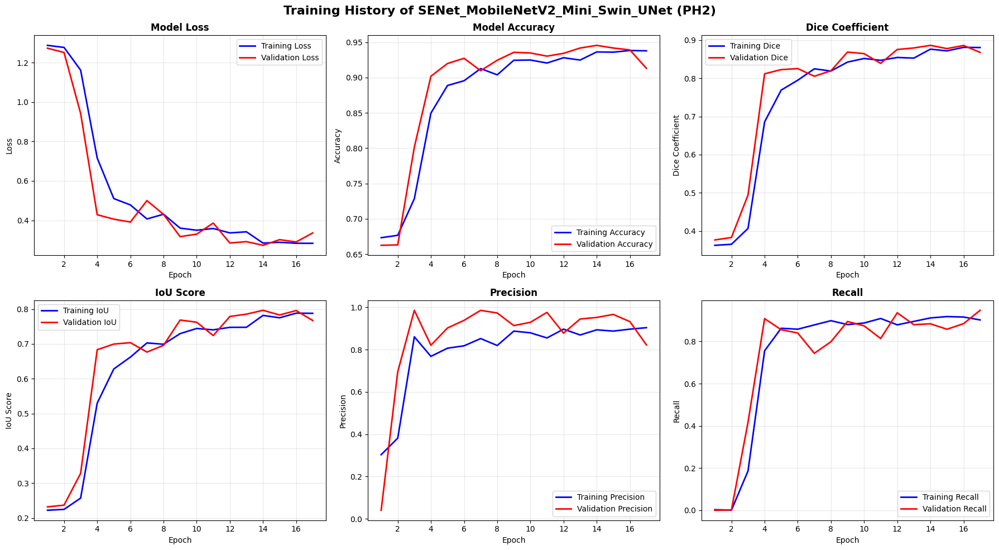

In [30]:
def plot_training_history(history):
    """Plot training and validation metrics"""
    
    # Get history data
    hist = history.history
    epochs_range = range(1, len(hist['loss']) + 1)
    
    # Create subplots
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('Training History of SENet_MobileNetV2_Mini_Swin_UNet (PH2)', fontsize=16, fontweight='bold')
    
    # Plot 1: Loss
    axes[0, 0].plot(epochs_range, hist['loss'], 'b-', label='Training Loss', linewidth=2)
    axes[0, 0].plot(epochs_range, hist['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    axes[0, 0].set_title('Model Loss', fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Plot 2: Accuracy
    axes[0, 1].plot(epochs_range, hist['accuracy'], 'b-', label='Training Accuracy', linewidth=2)
    axes[0, 1].plot(epochs_range, hist['val_accuracy'], 'r-', label='Validation Accuracy', linewidth=2)
    axes[0, 1].set_title('Model Accuracy', fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Accuracy')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Plot 3: Dice Coefficient
    axes[0, 2].plot(epochs_range, hist['dice_coefficient'], 'b-', label='Training Dice', linewidth=2)
    axes[0, 2].plot(epochs_range, hist['val_dice_coefficient'], 'r-', label='Validation Dice', linewidth=2)
    axes[0, 2].set_title('Dice Coefficient', fontweight='bold')
    axes[0, 2].set_xlabel('Epoch')
    axes[0, 2].set_ylabel('Dice Coefficient')
    axes[0, 2].legend()
    axes[0, 2].grid(True, alpha=0.3)
    
    # Plot 4: IoU Score
    axes[1, 0].plot(epochs_range, hist['iou_score'], 'b-', label='Training IoU', linewidth=2)
    axes[1, 0].plot(epochs_range, hist['val_iou_score'], 'r-', label='Validation IoU', linewidth=2)
    axes[1, 0].set_title('IoU Score', fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('IoU Score')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # Plot 5: Precision
    axes[1, 1].plot(epochs_range, hist['precision'], 'b-', label='Training Precision', linewidth=2)
    axes[1, 1].plot(epochs_range, hist['val_precision'], 'r-', label='Validation Precision', linewidth=2)
    axes[1, 1].set_title('Precision', fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Precision')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    # Plot 6: Recall
    axes[1, 2].plot(epochs_range, hist['recall'], 'b-', label='Training Recall', linewidth=2)
    axes[1, 2].plot(epochs_range, hist['val_recall'], 'r-', label='Validation Recall', linewidth=2)
    axes[1, 2].set_title('Recall', fontweight='bold')
    axes[1, 2].set_xlabel('Epoch')
    axes[1, 2].set_ylabel('Recall')
    axes[1, 2].legend()
    axes[1, 2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(history)

# **Compute Flops,Measure Inference Time,Memory Consumption**

Computing FLOPs...


I0000 00:00:1781001607.230628      58 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1781001607.230810      58 single_machine.cc:374] Starting new session
I0000 00:00:1781001607.232000      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.



=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
op: The nodes are operation kernel type, such as MatMul, Conv2D. Graph nodes belonging to the same type are aggregated together.
flops: Number of float operations. Note: Please read the implementation for th

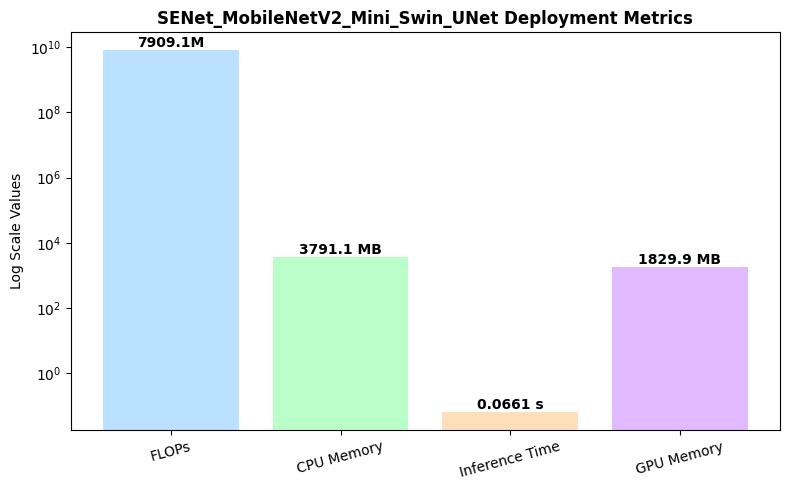

In [31]:
def plot_deployment_metrics(model):
    import tensorflow as tf
    import time
    import numpy as np
    import psutil
    import os
    import matplotlib.pyplot as plt
    from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

    # -----------------------------
    # 1. Compute FLOPs
    # -----------------------------
    def get_flops(model):
        input_shape = [1] + list(model.input_shape[1:])
        concrete_func = tf.function(lambda x: model(x))
        concrete_func = concrete_func.get_concrete_function(
            tf.TensorSpec(input_shape, model.inputs[0].dtype)
        )
        frozen_func = convert_variables_to_constants_v2(concrete_func)
        graph_def = frozen_func.graph.as_graph_def()

        with tf.Graph().as_default() as graph:
            tf.graph_util.import_graph_def(graph_def, name="")
            run_meta = tf.compat.v1.RunMetadata()
            opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
            flops = tf.compat.v1.profiler.profile(
                graph=graph, run_meta=run_meta, cmd='op', options=opts
            )
            return flops.total_float_ops

    print("Computing FLOPs...")
    flops = get_flops(model)

    # -----------------------------
    # 2. Inference Time (stable)
    # -----------------------------
    x_sample = np.random.rand(
        1,
        model.input_shape[1],
        model.input_shape[2],
        model.input_shape[3]
    ).astype(np.float32)

    # Warm-up runs (important for GPU stability)
    for _ in range(5):
        _ = model.predict(x_sample, verbose=0)

    # Measure average inference time
    runs = 10
    start_time = time.time()
    for _ in range(runs):
        _ = model.predict(x_sample, verbose=0)
    inference_time = (time.time() - start_time) / runs

    # -----------------------------
    # 3. Memory Usage
    # -----------------------------
    process = psutil.Process(os.getpid())
    cpu_memory = process.memory_info().rss / (1024 ** 2)  # MB

    gpu_memory = 0
    gpus = tf.config.list_physical_devices('GPU')

    if gpus:
        try:
            for i, gpu in enumerate(gpus):
                device_name = f"GPU:{i}"   # FIXED
                details = tf.config.experimental.get_memory_info(device_name)
                gpu_memory = details['peak'] / (1024 ** 2)  # MB
        except:
            gpu_memory = 0  # fallback if unsupported

    # -----------------------------
    # 4. Prepare Data
    # -----------------------------
    metrics = ['FLOPs', 'CPU Memory', 'Inference Time']
    values = [flops, cpu_memory, inference_time]

    if gpu_memory > 0:
        metrics.append('GPU Memory')
        values.append(gpu_memory)

    # -----------------------------
    # 5. Plot (Pastel Theme)
    # -----------------------------
    pastel_colors = ['#bae1ff', '#baffc9', '#ffdfba', '#e2baff']

    plt.figure(figsize=(8, 5))
    bars = plt.bar(metrics, values, color=pastel_colors[:len(metrics)])

    plt.yscale('log')
    plt.title("SENet_MobileNetV2_Mini_Swin_UNet Deployment Metrics", fontweight='bold')
    plt.ylabel("Log Scale Values")
    plt.xticks(rotation=15)

    # Annotate values
    for i, bar in enumerate(bars):
        height = bar.get_height()

        if metrics[i] == 'FLOPs':
            label = f'{height/1e6:.1f}M'
        elif 'Memory' in metrics[i]:
            label = f'{height:.1f} MB'
        else:
            label = f'{height:.4f} s'

        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            label,
            ha='center',
            va='bottom',
            fontweight='bold'
        )

    plt.tight_layout()
    plt.savefig('/kaggle/working/deployment_metrics.png', dpi=300, bbox_inches='tight')
    plt.show()


# Run
plot_deployment_metrics(model)

# **TTA**

TTA pass 1/5
TTA pass 2/5
TTA pass 3/5
TTA pass 4/5
TTA pass 5/5


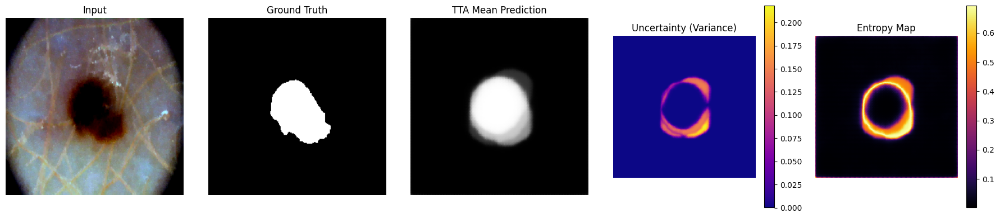

In [32]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import gc

# ── reduce N_TTA to keep memory manageable ──
N_TTA = 5

def augment_image(img):
    img = np.array(img)
    if img.ndim != 3:
        raise ValueError(f"Bad image shape: {img.shape}")
    if np.random.rand() > 0.5:
        img = np.flip(img, axis=1)
    if np.random.rand() > 0.5:
        img = np.flip(img, axis=0)
    return img


def tta_segmentation(model, X, n_tta=N_TTA, batch_size=8):
    """
    Memory-safe TTA: accumulates a running mean/variance instead
    of stacking all passes into a giant array.
    """
    X = np.array(X, dtype=np.float32)
    if X.shape[-1] != 3:
        raise ValueError(f"Expected (H,W,3) but got: {X.shape}")

    N = len(X)
    pred_shape = list(X.shape)
    pred_shape[-1] = 1          # output is H×W×1

    mean_acc = np.zeros([N] + pred_shape[1:], dtype=np.float64)
    M2_acc   = np.zeros([N] + pred_shape[1:], dtype=np.float64)

    all_preds = []   # kept only for compatibility; use mean/var from streaming

    for t in range(n_tta):
        print(f"TTA pass {t+1}/{n_tta}")

        preds_t = []

        for i in range(0, N, batch_size):
            batch = np.stack([augment_image(X[j]) for j in range(i, min(i+batch_size, N))])
            pred  = model.predict(batch, verbose=0)
            preds_t.append(pred)

        preds_t = np.concatenate(preds_t, axis=0)   # (N, H, W, 1)

        # Welford online mean/variance update
        delta      = preds_t - mean_acc
        mean_acc  += delta / (t + 1)
        delta2     = preds_t - mean_acc
        M2_acc    += delta * delta2

        all_preds.append(preds_t)
        gc.collect()

    var_acc    = M2_acc / n_tta
    all_preds  = np.stack(all_preds, axis=1)        # kept for downstream compat

    return mean_acc.astype(np.float32), var_acc.astype(np.float32), all_preds


# Run TTA
tta_mean, tta_var, tta_all = tta_segmentation(model, X_test)

# Pixel-wise entropy
epsilon = 1e-6
entropy_map = -(
    tta_mean * np.log(tta_mean + epsilon) +
    (1 - tta_mean) * np.log(1 - tta_mean + epsilon)
)

def plot_segmentation_uncertainty(X, y_true, mean_pred, var_pred, entropy_map, idx=0):
    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    axes[0].imshow(X[idx].squeeze(), cmap='gray');   axes[0].set_title("Input")
    axes[1].imshow(y_true[idx].squeeze(), cmap='gray'); axes[1].set_title("Ground Truth")
    axes[2].imshow(mean_pred[idx].squeeze(), cmap='gray'); axes[2].set_title("TTA Mean Prediction")
    im3 = axes[3].imshow(var_pred[idx].squeeze(), cmap='plasma'); axes[3].set_title("Uncertainty (Variance)")
    plt.colorbar(im3, ax=axes[3])
    im4 = axes[4].imshow(entropy_map[idx].squeeze(), cmap='inferno'); axes[4].set_title("Entropy Map")
    plt.colorbar(im4, ax=axes[4])
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()

plot_segmentation_uncertainty(X_test, y_test, tta_mean, tta_var, entropy_map, idx=4)


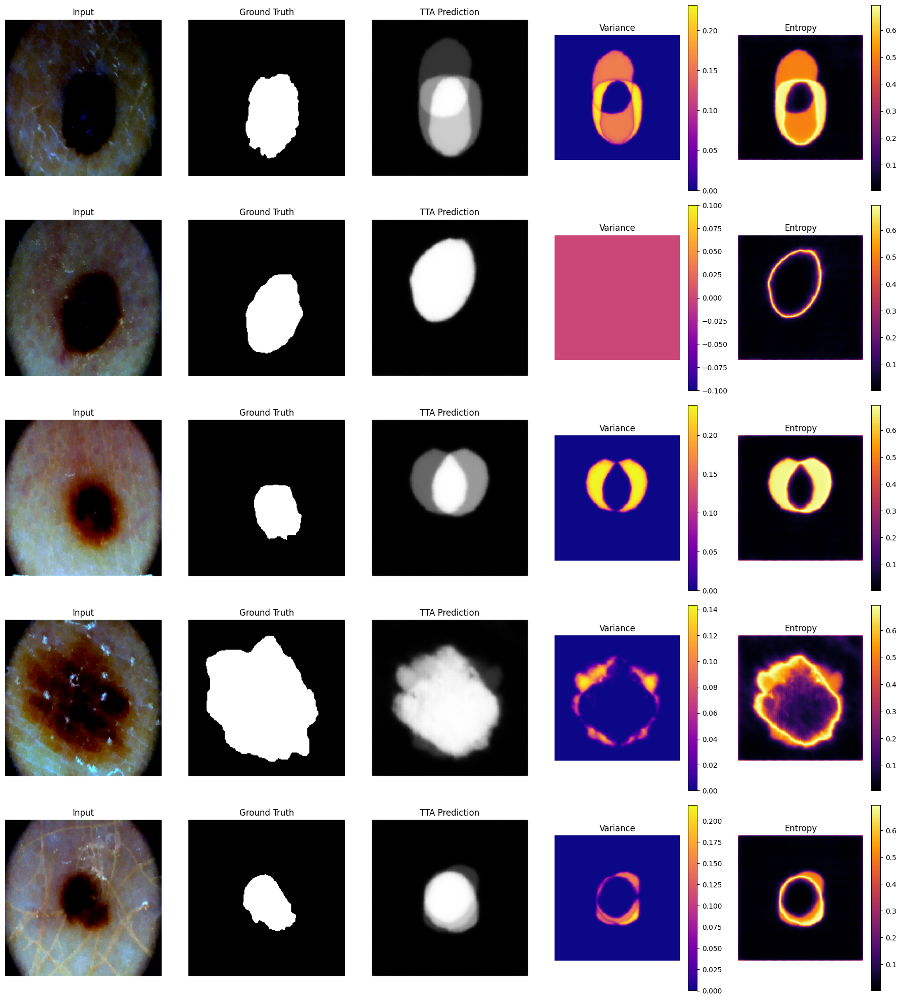

In [33]:
# Multi-sample uncertainty visualisation (reuses tta_mean / tta_var / entropy_map from previous cell)

def plot_multiple_uncertainty(X, y_true, mean_pred, var_pred, entropy_map, num_samples=5):
    fig, axes = plt.subplots(num_samples, 5, figsize=(18, 4 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)
    for i in range(num_samples):
        axes[i, 0].imshow(X[i].squeeze(), cmap='gray');        axes[i, 0].set_title("Input")
        axes[i, 1].imshow(y_true[i].squeeze(), cmap='gray');   axes[i, 1].set_title("Ground Truth")
        axes[i, 2].imshow(mean_pred[i].squeeze(), cmap='gray');axes[i, 2].set_title("TTA Prediction")
        im1 = axes[i, 3].imshow(var_pred[i].squeeze(), cmap='plasma');   axes[i, 3].set_title("Variance")
        plt.colorbar(im1, ax=axes[i, 3])
        im2 = axes[i, 4].imshow(entropy_map[i].squeeze(), cmap='inferno');axes[i, 4].set_title("Entropy")
        plt.colorbar(im2, ax=axes[i, 4])
        for j in range(5): axes[i, j].axis('off')
    plt.tight_layout(); plt.show()

plot_multiple_uncertainty(X_test, y_test, tta_mean, tta_var, entropy_map, num_samples=5)


# **MC Dropout**

Running MC Dropout...

MC pass 1/5

MC pass 2/5

MC pass 3/5

MC pass 4/5

MC pass 5/5


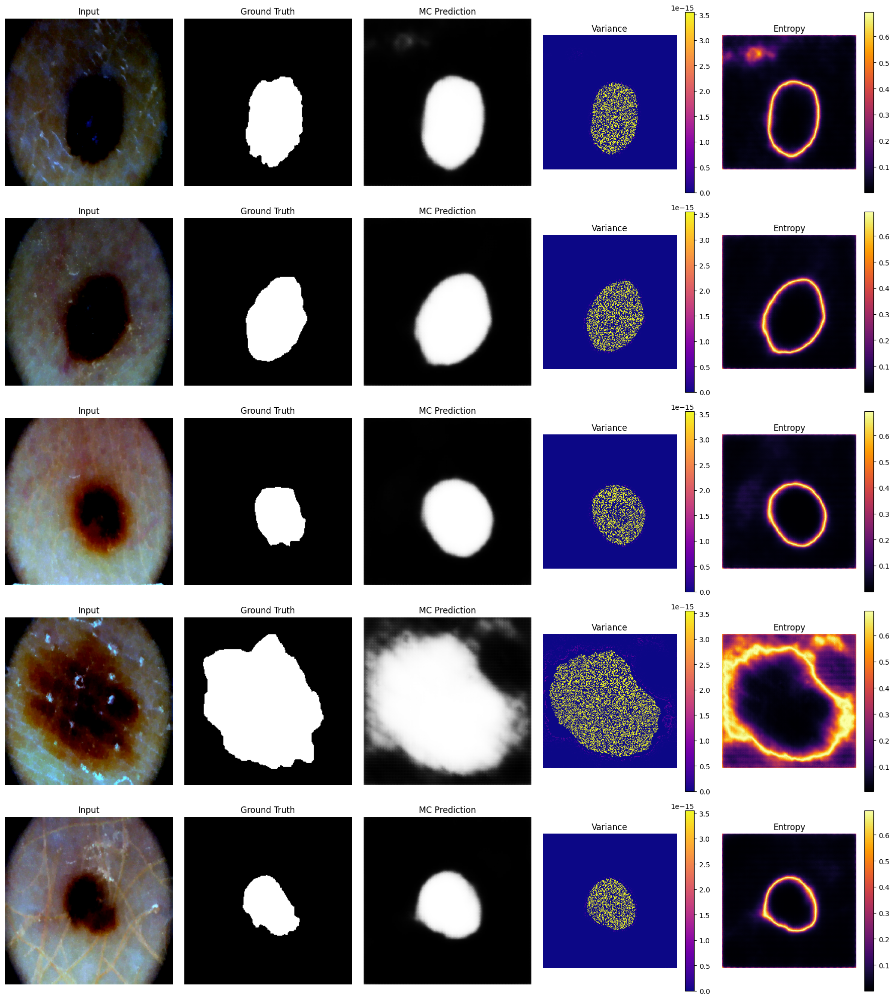

In [34]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import gc

N_MC       = 5
BATCH_SIZE = 4   # keep small to avoid OOM


def mc_dropout_segmentation(model, X, n_mc=N_MC, batch_size=BATCH_SIZE):
    X = np.array(X, dtype=np.float32)
    if X.shape[-1] != 3:
        raise ValueError(f"Expected (H,W,3) but got {X.shape}")

    N = len(X)
    all_preds = []

    for t in range(n_mc):
        preds_t = []
        print(f"\nMC pass {t+1}/{n_mc}")

        for i in range(0, N, batch_size):
            batch = X[i:i + batch_size]
            pred  = model(batch, training=True)   # dropout ON
            preds_t.append(pred.numpy())

        preds_t = np.concatenate(preds_t, axis=0)
        all_preds.append(preds_t)
        gc.collect()

    all_preds = np.stack(all_preds, axis=1)   # (N, T, H, W, 1)
    mean_pred = np.mean(all_preds, axis=1)
    var_pred  = np.var(all_preds,  axis=1)

    return mean_pred, var_pred, all_preds


print("Running MC Dropout...")
mc_mean, mc_var, mc_all = mc_dropout_segmentation(model, X_test)

epsilon = 1e-6
mc_entropy = -(
    mc_mean * np.log(mc_mean + epsilon) +
    (1 - mc_mean) * np.log(1 - mc_mean + epsilon)
)


def plot_mc_uncertainty(X, y_true, mean_pred, var_pred, entropy_map, num_samples=5):
    fig, axes = plt.subplots(num_samples, 5, figsize=(18, 4 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)
    for i in range(num_samples):
        axes[i, 0].imshow(X[i].squeeze(), cmap='gray');        axes[i, 0].set_title("Input")
        axes[i, 1].imshow(y_true[i].squeeze(), cmap='gray');   axes[i, 1].set_title("Ground Truth")
        axes[i, 2].imshow(mean_pred[i].squeeze(), cmap='gray');axes[i, 2].set_title("MC Prediction")
        im1 = axes[i, 3].imshow(var_pred[i].squeeze(), cmap='plasma');    axes[i, 3].set_title("Variance")
        plt.colorbar(im1, ax=axes[i, 3])
        im2 = axes[i, 4].imshow(entropy_map[i].squeeze(), cmap='inferno');axes[i, 4].set_title("Entropy")
        plt.colorbar(im2, ax=axes[i, 4])
        for j in range(5): axes[i, j].axis('off')
    plt.tight_layout(); plt.show()


plot_mc_uncertainty(X_test, y_test, mc_mean, mc_var, mc_entropy, num_samples=5)


# **EXPECTED CALIBRATION ERROR (ECE)**

ECE Score: 0.013338


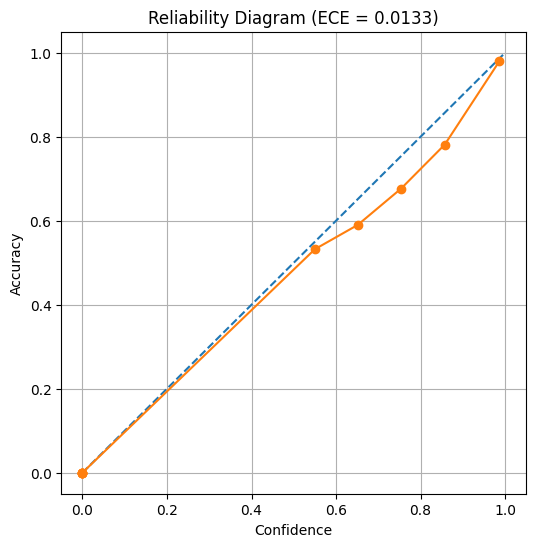

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# EXPECTED CALIBRATION ERROR (ECE)
# FOR SEGMENTATION
# ============================================================
def compute_ece_segmentation(y_true, y_prob, n_bins=10):

    y_true = y_true.flatten()
    y_prob = y_prob.flatten()

    # predicted class
    y_pred = (y_prob >= 0.5).astype(np.float32)

    # confidence = max(p, 1-p)
    confidence = np.maximum(y_prob, 1 - y_prob)

    correctness = (y_pred == y_true).astype(np.float32)

    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)

    ece = 0.0

    bin_accs = []
    bin_confs = []
    bin_counts = []

    for i in range(n_bins):

        bin_lower = bin_edges[i]
        bin_upper = bin_edges[i + 1]

        in_bin = (confidence > bin_lower) & (confidence <= bin_upper)

        prop_in_bin = np.mean(in_bin)

        if prop_in_bin > 0:

            acc = np.mean(correctness[in_bin])
            conf = np.mean(confidence[in_bin])

            ece += np.abs(conf - acc) * prop_in_bin

            bin_accs.append(acc)
            bin_confs.append(conf)
            bin_counts.append(np.sum(in_bin))

        else:
            bin_accs.append(0)
            bin_confs.append(0)
            bin_counts.append(0)

    return ece, bin_accs, bin_confs, bin_counts


# ============================================================
# RELIABILITY DIAGRAM
# ============================================================
def plot_reliability_diagram(bin_accs, bin_confs, ece_score, n_bins=10):

    plt.figure(figsize=(6, 6))

    # perfect calibration line
    plt.plot([0, 1], [0, 1], linestyle='--')

    # model calibration curve
    plt.plot(bin_confs, bin_accs, marker='o')

    plt.xlabel("Confidence")
    plt.ylabel("Accuracy")

    plt.title(f"Reliability Diagram (ECE = {ece_score:.4f})")

    plt.grid(True)
    plt.show()


# ============================================================
# COMPUTE ECE
# ============================================================
ece_score, bin_accs, bin_confs, bin_counts = compute_ece_segmentation(
    y_test,
    mc_mean,
    n_bins=10
)

print(f"ECE Score: {ece_score:.6f}")


# ============================================================
# PLOT
# ============================================================
plot_reliability_diagram(
    bin_accs,
    bin_confs,
    ece_score
)

# **Create comprehensive results summary visualization**

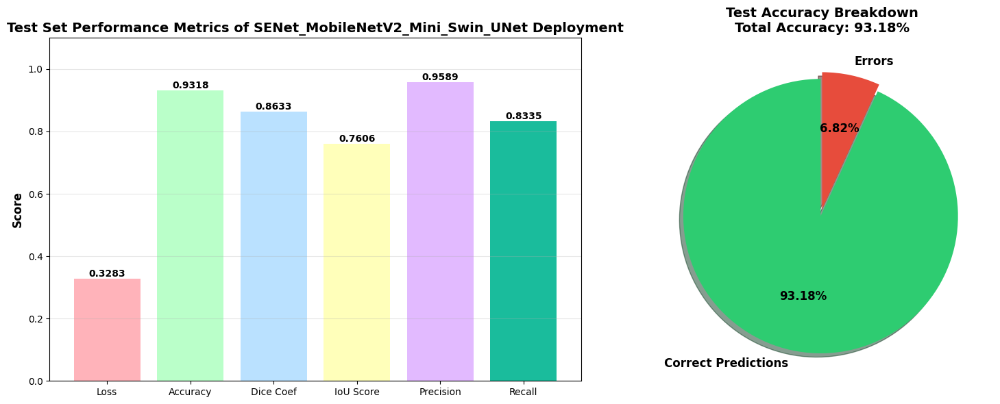

In [36]:
def plot_test_results_summary(test_results):
    """Create a comprehensive visualization of test results"""

    metrics_names = ['Loss', 'Accuracy', 'Dice Coef', 'IoU Score', 'Precision', 'Recall']
    metrics_values = test_results

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Bar chart for metrics
    colors = ['#ffb3ba', '#baffc9', '#bae1ff', '#ffffba', '#e2baff', '#1abc9c']
    bars = axes[0].bar(metrics_names, metrics_values, color=colors, linewidth=1.5)
    axes[0].set_ylabel('Score', fontsize=12, fontweight='bold')
    axes[0].set_title('Test Set Performance Metrics of SENet_MobileNetV2_Mini_Swin_UNet Deployment', fontsize=14, fontweight='bold')
    axes[0].set_ylim([0, 1.1])
    axes[0].grid(True, alpha=0.3, axis='y')

    # Add value labels on bars
    for bar, value in zip(bars, metrics_values):
        height = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{value:.4f}',
                    ha='center', va='bottom', fontweight='bold', fontsize=10)

    # Pie chart for accuracy breakdown
    accuracy_percent = test_results[1] * 100
    error_percent = 100 - accuracy_percent

    pie_colors = ['#2ecc71', '#e74c3c']
    explode = (0.05, 0)

    axes[1].pie([accuracy_percent, error_percent],
                labels=['Correct Predictions', 'Errors'],
                autopct='%1.2f%%',
                startangle=90,
                colors=pie_colors,
                explode=explode,
                shadow=True,
                textprops={'fontsize': 12, 'fontweight': 'bold'})
    axes[1].set_title(f'Test Accuracy Breakdown\nTotal Accuracy: {accuracy_percent:.2f}%',
                     fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.show()

plot_test_results_summary(test_results)

# **Generate predictions on test set**

In [37]:
print("Generating predictions on test set...")

# ── Memory fix: predict via tf.data so TF streams batches ──
test_pred_ds = tf.data.Dataset.from_tensor_slices(X_test) \
    .batch(CONFIG['BATCH_SIZE']) \
    .prefetch(tf.data.AUTOTUNE)

y_pred = model.predict(test_pred_ds, verbose=1)

y_pred_binary = (y_pred > 0.5).astype(np.float32)

print(f"\nPredictions shape : {y_pred.shape}")
print(f"Predictions range : [{y_pred.min():.3f}, {y_pred.max():.3f}]")
print(f"Binary predictions unique values: {np.unique(y_pred_binary)}")


Generating predictions on test set...
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step

Predictions shape : (30, 224, 224, 1)
Predictions range : [0.000, 1.000]
Binary predictions unique values: [0. 1.]


# **Visualize prediction results**

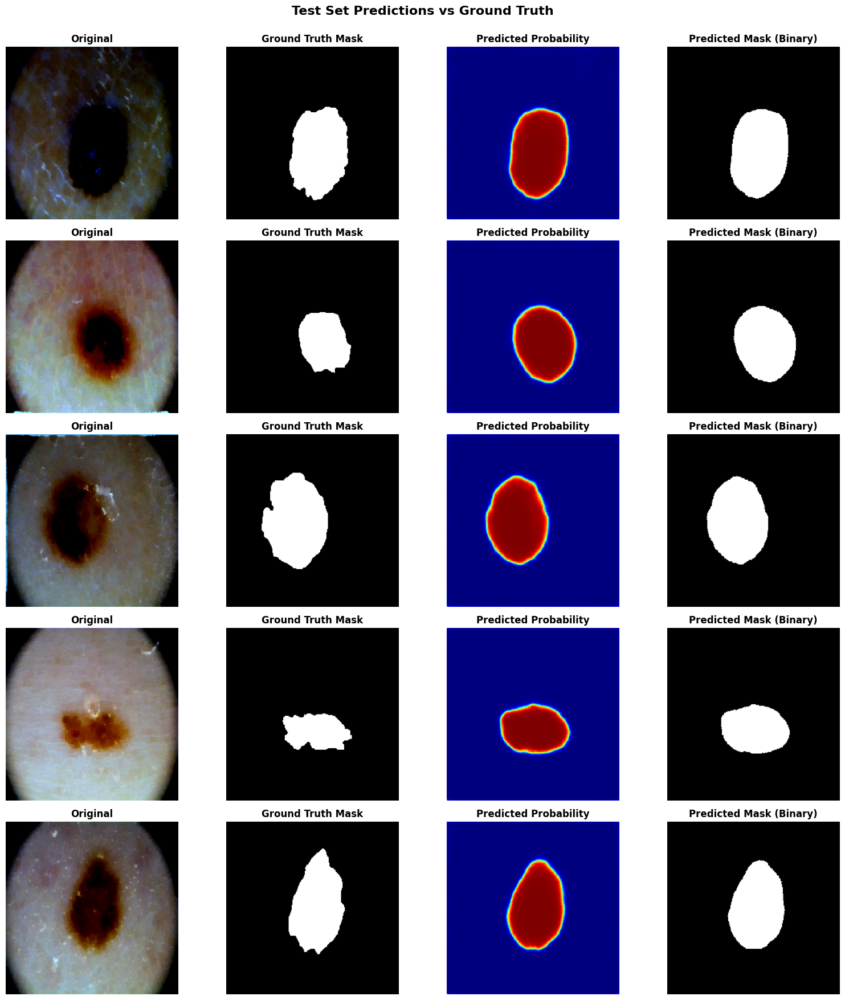

In [38]:
def visualize_predictions(X_test, y_test, y_pred, num_samples=5):
    """Display random test samples with predictions and ground truth"""
    
    random_indices = random.sample(range(len(X_test)), num_samples)
    
    fig, axes = plt.subplots(num_samples, 4, figsize=(16, num_samples * 3.5))
    
    for idx, test_idx in enumerate(random_indices):
        # Original image
        axes[idx, 0].imshow(X_test[test_idx].squeeze(), cmap='gray')
        axes[idx, 0].set_title('Original', fontweight='bold')
        axes[idx, 0].axis('off')
        
        # Ground truth mask
        axes[idx, 1].imshow(y_test[test_idx].squeeze(), cmap='gray')
        axes[idx, 1].set_title('Ground Truth Mask', fontweight='bold')
        axes[idx, 1].axis('off')
        
        # Predicted mask (probability)
        axes[idx, 2].imshow(y_pred[test_idx].squeeze(), cmap='jet', vmin=0, vmax=1)
        axes[idx, 2].set_title('Predicted Probability', fontweight='bold')
        axes[idx, 2].axis('off')
        
        # Predicted mask (binary)
        pred_binary = (y_pred[test_idx] > 0.5).astype(np.float32)
        axes[idx, 3].imshow(pred_binary.squeeze(), cmap='gray')
        axes[idx, 3].set_title('Predicted Mask (Binary)', fontweight='bold')
        axes[idx, 3].axis('off')
    
    plt.suptitle('Test Set Predictions vs Ground Truth', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.savefig('/kaggle/working/predictions_visualization.png', dpi=300, bbox_inches='tight')
    plt.show()

visualize_predictions(X_test, y_test, y_pred, num_samples=5)

# **Calculate detailed per-image metrics**

In [39]:
def calculate_per_image_metrics(y_true, y_pred_binary):
    """Calculate Dice and IoU for each image"""
    
    dice_scores = []
    iou_scores = []
    
    for i in range(len(y_true)):
        true_mask = y_true[i].flatten()
        pred_mask = y_pred_binary[i].flatten()
        
        intersection = np.sum(true_mask * pred_mask)
        union = np.sum(true_mask) + np.sum(pred_mask) - intersection
        
        # Dice coefficient
        dice = (2. * intersection + 1e-6) / (np.sum(true_mask) + np.sum(pred_mask) + 1e-6)
        dice_scores.append(dice)
        
        # IoU score
        iou = (intersection + 1e-6) / (union + 1e-6)
        iou_scores.append(iou)
    
    return np.array(dice_scores), np.array(iou_scores)

# Calculate metrics
dice_scores, iou_scores = calculate_per_image_metrics(y_test, y_pred_binary)

print("Per-Image Metrics Statistics:")
print("=" * 60)
print(f"Dice Coefficient - Mean: {dice_scores.mean():.4f}, Std: {dice_scores.std():.4f}")
print(f"Dice Coefficient - Min: {dice_scores.min():.4f}, Max: {dice_scores.max():.4f}")
print(f"\nIoU Score - Mean: {iou_scores.mean():.4f}, Std: {iou_scores.std():.4f}")
print(f"IoU Score - Min: {iou_scores.min():.4f}, Max: {iou_scores.max():.4f}")
print("=" * 60)

Per-Image Metrics Statistics:
Dice Coefficient - Mean: 0.8893, Std: 0.1366
Dice Coefficient - Min: 0.2052, Max: 0.9740

IoU Score - Mean: 0.8194, Std: 0.1547
IoU Score - Min: 0.1143, Max: 0.9493


# **Visualize per-image metrics distribution**

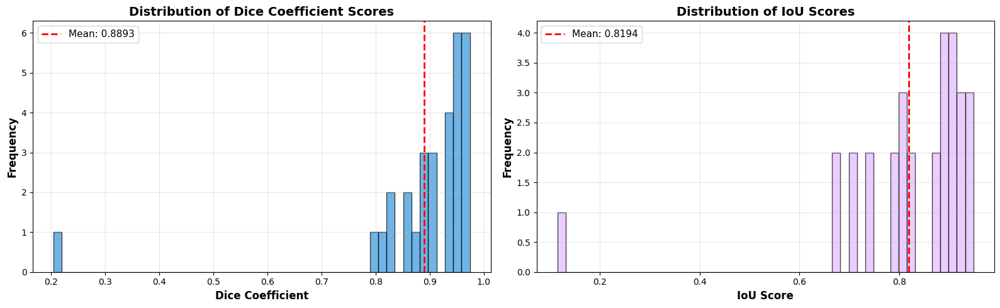

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histogram for Dice Coefficient
axes[0].hist(dice_scores, bins=50, color='#3495db', edgecolor='black', alpha=0.7)
axes[0].axvline(dice_scores.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {dice_scores.mean():.4f}')
axes[0].set_xlabel('Dice Coefficient', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[0].set_title('Distribution of Dice Coefficient Scores', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Histogram for IoU Score
axes[1].hist(iou_scores, bins=50, color='#e2baff', edgecolor='black', alpha=0.7)
axes[1].axvline(iou_scores.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {iou_scores.mean():.4f}')
axes[1].set_xlabel('IoU Score', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[1].set_title('Distribution of IoU Scores', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/metrics_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# **Create overlay visualizations (mask overlay)**

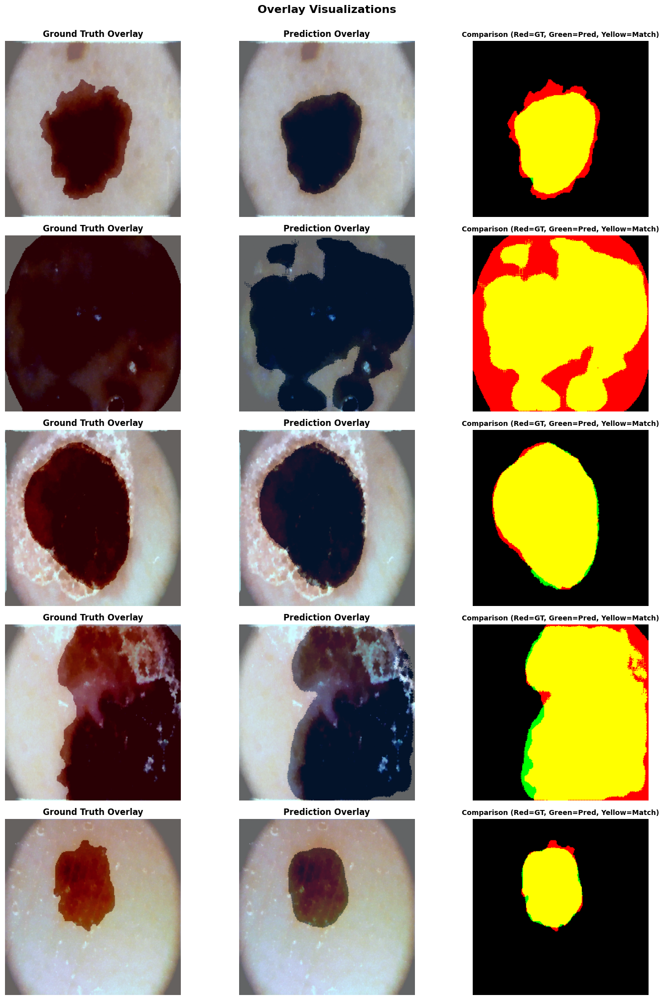

In [41]:
def create_overlay_visualization(X_test, y_test, y_pred, num_samples=5):
    """Create overlay visualizations of predictions on original images"""
    
    random_indices = random.sample(range(len(X_test)), num_samples)
    
    fig, axes = plt.subplots(num_samples, 3, figsize=(15, num_samples * 4))
    
    for idx, test_idx in enumerate(random_indices):
        img = X_test[test_idx].squeeze()
        true_mask = y_test[test_idx].squeeze()
        pred_mask = (y_pred[test_idx].squeeze() > 0.5).astype(np.float32)
        
        # Original with ground truth overlay
        axes[idx, 0].imshow(img, cmap='gray')
        axes[idx, 0].imshow(true_mask, cmap='Reds', alpha=0.4)
        axes[idx, 0].set_title('Ground Truth Overlay', fontweight='bold')
        axes[idx, 0].axis('off')
        
        # Original with prediction overlay
        axes[idx, 1].imshow(img, cmap='gray')
        axes[idx, 1].imshow(pred_mask, cmap='Blues', alpha=0.4)
        axes[idx, 1].set_title('Prediction Overlay', fontweight='bold')
        axes[idx, 1].axis('off')
        
        # Comparison: Ground truth vs Prediction
        comparison = np.zeros((img.shape[0], img.shape[1], 3))
        comparison[:, :, 0] = true_mask  # Red channel for ground truth
        comparison[:, :, 1] = pred_mask   # Green channel for prediction
        # Yellow areas = both agree, Red = only ground truth, Green = only prediction
        
        axes[idx, 2].imshow(comparison)
        axes[idx, 2].set_title('Comparison (Red=GT, Green=Pred, Yellow=Match)', fontweight='bold', fontsize=10)
        axes[idx, 2].axis('off')
    
    plt.suptitle('Overlay Visualizations', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.savefig('/kaggle/working/overlay_visualization.png', dpi=300, bbox_inches='tight')
    plt.show()

create_overlay_visualization(X_test, y_test, y_pred, num_samples=5)


# **Ablation Study**

This section systematically evaluates the contribution of each key component in the **SENet_MobileNetV2_Mini_Swin_UNet** architecture and preprocessing pipeline.

We ablate the following components:

| # | Variant | What is removed / changed |
|---|---------|---------------------------|
| 1 | **Full Model (Baseline)** | All components active |
| 2 | **No SE Blocks** | Squeeze-and-Excitation attention removed |
| 3 | **No Swin Bottleneck** | Mini-Swin transformer replaced with plain Conv |
| 4 | **No SE + No Swin** | Both attention mechanisms removed |
| 5 | **No Hair Removal** | Hair-removal preprocessing step skipped |
| 6 | **No Color Constancy** | Shades-of-Gray normalization skipped |
| 7 | **No Augmentation** | Albumentations pipeline disabled |
| 8 | **BCE Loss only** | Dice component removed from combined loss |

Each variant is trained for a **reduced number of epochs** (fast ablation) on the same train/val/test split and evaluated on Dice Coefficient and IoU Score.

In [43]:
# ============================================================
# ABLATION STUDY — CONFIG & SHARED HELPERS
# ============================================================
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# ── Reduced epochs for fast ablation (increase for full runs) ──
ABLATION_EPOCHS   = 30
ABLATION_PATIENCE = 10
ABLATION_LR       = 1e-4

IMG_H = CONFIG['IMG_HEIGHT']
IMG_W = CONFIG['IMG_WIDTH']
IMG_C = CONFIG['IMG_CHANNELS']
BS    = CONFIG['BATCH_SIZE']

print(f"Ablation epochs   : {ABLATION_EPOCHS}")
print(f"Early-stop patience: {ABLATION_PATIENCE}")
print(f"Image size        : {IMG_H}x{IMG_W}x{IMG_C}")
print(f"Batch size        : {BS}")


# ── Shared loss / metrics (reused from main notebook) ──
def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.keras.backend.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (
        tf.keras.backend.sum(y_true_f) + tf.keras.backend.sum(y_pred_f) + smooth)

def iou_score(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.keras.backend.sum(y_true_f * y_pred_f)
    union = (tf.keras.backend.sum(y_true_f) +
             tf.keras.backend.sum(y_pred_f) - intersection)
    return (intersection + smooth) / (union + smooth)

def dice_loss(y_true, y_pred):
    return 1 - dice_coefficient(y_true, y_pred)

def combined_loss(y_true, y_pred):
    bce  = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    dice = dice_loss(y_true, y_pred)
    return bce + dice

def bce_only_loss(y_true, y_pred):
    """Ablation variant: Binary Cross-Entropy only (no Dice)."""
    return tf.keras.losses.binary_crossentropy(y_true, y_pred)


# ── Callbacks factory ──
def make_callbacks():
    return [
        EarlyStopping(
            monitor='val_dice_coefficient',
            mode='max',
            patience=ABLATION_PATIENCE,
            restore_best_weights=True,
            verbose=0
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=ABLATION_PATIENCE // 2,
            min_lr=1e-7,
            verbose=0
        ),
    ]

print("Shared helpers ready.")


Ablation epochs   : 30
Early-stop patience: 10
Image size        : 224x224x3
Batch size        : 8
Shared helpers ready.


In [44]:
# ============================================================
# ABLATION MODEL VARIANTS
# ============================================================

# ── Shared utilities ──
def resize_to_match(x, ref):
    return layers.Lambda(
        lambda t: tf.image.resize(t[0], tf.shape(t[1])[1:3])
    )([x, ref])


# ── SE Block ──
def se_block(input_tensor, ratio=16):
    channels = input_tensor.shape[-1]
    se = layers.GlobalAveragePooling2D()(input_tensor)
    se = layers.Dense(max(channels // ratio, 4), activation='relu')(se)
    se = layers.Dense(channels, activation='sigmoid')(se)
    se = layers.Reshape((1, 1, channels))(se)
    return layers.Multiply()([input_tensor, se])


# ── Mini-Swin Bottleneck ──
def mini_swin_block(x, num_heads=4, mlp_dim=256):
    shortcut = x
    c = x.shape[-1]
    x    = layers.LayerNormalization()(x)
    attn = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=max(c // num_heads, 8)
    )(x, x)
    x   = layers.Add()([shortcut, attn])
    mlp = layers.LayerNormalization()(x)
    mlp = layers.Dense(mlp_dim, activation='relu')(mlp)
    mlp = layers.Dense(c)(mlp)
    x   = layers.Add()([x, mlp])
    return x


def swin_bottleneck(x):
    x = layers.Conv2D(192, 1, padding='same', activation='relu')(x)
    shape = tf.keras.backend.int_shape(x)
    h, w, c = shape[1], shape[2], shape[3]
    x = layers.Reshape((h * w, c))(x)
    x = mini_swin_block(x)
    x = mini_swin_block(x)
    x = layers.Reshape((h, w, c))(x)
    x = layers.Conv2D(320, 1, padding='same', activation='relu')(x)
    return x


def plain_bottleneck(x):
    """Ablation: replace Swin transformer with plain Conv bottleneck."""
    x = layers.Conv2D(192, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(320, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    return x


# ── Generic U-Net builder with ablation flags ──
def build_ablation_unet(
    img_height, img_width, img_channels,
    use_se=True,
    use_swin=True,
):
    """
    Build a MobileNetV2 U-Net with optional SE and Swin components.

    Parameters
    ----------
    use_se   : include Squeeze-and-Excitation blocks
    use_swin : use Mini-Swin bottleneck; if False, use plain Conv bottleneck
    """
    inputs = layers.Input((img_height, img_width, img_channels))
    x = inputs

    base_model = MobileNetV2(
        include_top=False, weights='imagenet', input_tensor=x
    )
    for layer in base_model.layers[:-80]:
        layer.trainable = False
    for layer in base_model.layers[-80:]:
        layer.trainable = True

    s1 = base_model.get_layer('block_1_expand_relu').output
    s2 = base_model.get_layer('block_3_expand_relu').output
    s3 = base_model.get_layer('block_6_expand_relu').output
    s4 = base_model.get_layer('block_13_expand_relu').output
    b1 = base_model.output

    # Optional SE on skip connections
    if use_se:
        s1, s2, s3, s4, b1 = (se_block(t) for t in [s1, s2, s3, s4, b1])

    # Optional Swin bottleneck
    b1 = swin_bottleneck(b1) if use_swin else plain_bottleneck(b1)

    # Decoder
    def dec_block(up_in, skip, filters, use_se_flag):
        u = layers.Conv2DTranspose(filters, 2, strides=2, padding='same')(up_in)
        s = resize_to_match(skip, u)
        u = layers.concatenate([u, s])
        c = layers.Conv2D(filters, 3, activation='relu', padding='same')(u)
        if use_se_flag:
            c = se_block(c)
        return c

    c1 = dec_block(b1, s4, 320, use_se)
    c2 = dec_block(c1, s3, 192, use_se)
    c3 = dec_block(c2, s2,  96, use_se)
    c4 = dec_block(c3, s1,  64, use_se)

    u_final = layers.Conv2DTranspose(32, 2, strides=2, padding='same')(c4)
    u_final = layers.Conv2D(32, 3, activation='relu', padding='same')(u_final)
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(u_final)

    return models.Model(inputs, outputs)


print("Ablation model builders defined.")


Ablation model builders defined.


In [46]:
# ============================================================
# ABLATION DATA GENERATORS
# Variants control which preprocessing steps are active.
# ============================================================
import albumentations as A
import cv2

# Full augmentation pipeline (same as main notebook)
_augment_full = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Rotate(limit=45, border_mode=cv2.BORDER_REFLECT_101, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20,
                         val_shift_limit=10, p=0.4),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.ElasticTransform(alpha=1, sigma=50, alpha_affine=30,
                       border_mode=cv2.BORDER_REFLECT_101, p=0.15),
    A.GridDistortion(num_steps=5, distort_limit=0.2, p=0.15),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16,
                    min_holes=1, fill_value=0, p=0.2),
])

# Minimal pipeline (flips only — used for the 'No Augmentation' ablation)
_augment_none = A.Compose([])


def ablation_generator(
    images, masks, batch_size,
    use_augmentation=True,
):
    """
    Data generator for ablation experiments.

    Parameters
    ----------
    use_augmentation : apply the full Albumentations pipeline
    """
    aug_pipeline = _augment_full if use_augmentation else _augment_none

    n = len(images)
    indices = np.arange(n)

    while True:
        np.random.shuffle(indices)
        for start in range(0, n - batch_size + 1, batch_size):
            batch_idx = indices[start : start + batch_size]
            batch_imgs, batch_masks = [], []

            for i in batch_idx:
                img  = images[i]
                mask = masks[i]

                img_u8  = np.clip((img + 1.0) * 127.5, 0, 255).astype(np.uint8)
                mask_u8 = (mask.squeeze() > 0).astype(np.uint8)

                aug = aug_pipeline(image=img_u8, mask=mask_u8)

                aug_img  = mobilenet_preprocess(aug['image'].astype(np.float32))
                aug_mask = aug['mask']
                if aug_mask.ndim == 2:
                    aug_mask = np.expand_dims(aug_mask, axis=-1)
                aug_mask = (aug_mask > 0).astype(np.float32)

                batch_imgs.append(aug_img)
                batch_masks.append(aug_mask)

            yield (np.array(batch_imgs, dtype=np.float32),
                   np.array(batch_masks, dtype=np.float32))


# Validation dataset (same for every variant)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)) \
    .batch(BS).prefetch(tf.data.AUTOTUNE)

# Test dataset (same for every variant)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)) \
    .batch(BS).prefetch(tf.data.AUTOTUNE)

print("Ablation data generators ready.")


Ablation data generators ready.


In [47]:
def run_ablation_variant(
    name,
    model,
    train_gen,
    loss_fn=combined_loss,
):
    print(f"\n{'='*60}")
    print(f"  Variant: {name}")
    print(f"{'='*60}")

    # Define metrics explicitly so position is guaranteed
    metrics_list = [
        'accuracy',
        dice_coefficient,
        iou_score,
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=ABLATION_LR),
        loss=loss_fn,
        metrics=metrics_list,
    )

    steps = len(X_train) // BS
    t0 = time.time()

    history = model.fit(
        train_gen,
        steps_per_epoch=steps,
        validation_data=val_ds,
        epochs=ABLATION_EPOCHS,
        callbacks=make_callbacks(),
        verbose=1,
    )

    train_time = time.time() - t0

    # ── Evaluate returns [loss, acc, dice, iou, precision, recall] by position ──
    results = model.evaluate(test_ds, verbose=1)
    print(f"  Raw results: {results}")

    # Positional extraction — safe regardless of Keras metric naming
    loss_val  = results[0]
    acc_val   = results[1]
    dice_val  = results[2]
    iou_val   = results[3]
    prec_val  = results[4]
    rec_val   = results[5]

    print(f"  Test Dice : {dice_val:.4f}")
    print(f"  Test IoU  : {iou_val:.4f}")
    print(f"  Train time: {train_time/60:.1f} min")

    del model
    tf.keras.backend.clear_session()
    gc.collect()

    return {
        'name'       : name,
        'loss'       : loss_val,
        'accuracy'   : acc_val,
        'dice'       : dice_val,
        'iou'        : iou_val,
        'precision'  : prec_val,
        'recall'     : rec_val,
        'train_time' : train_time,
        'history'    : history.history,
    }

## Variant 1 — Full Model (Baseline)
All components active: SE blocks + Mini-Swin bottleneck + Hair Removal + Color Constancy + Augmentation + Combined Loss.

In [48]:
m1 = build_ablation_unet(IMG_H, IMG_W, IMG_C, use_se=True, use_swin=True)
g1 = ablation_generator(X_train, y_train, BS, use_augmentation=True)
r1 = run_ablation_variant('Full Model (Baseline)', m1, g1, loss_fn=combined_loss)
# ablation_results.append(r1)



  Variant: Full Model (Baseline)
Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 62s 866ms/step - accuracy: 0.5795 - dice_coefficient: 0.3821 - iou_score: 0.2379 - loss: 1.3036 - precision: 0.3392 - recall: 0.3308 - val_accuracy: 0.6581 - val_dice_coefficient: 0.3917 - val_iou_score: 0.2437 - val_loss: 1.2783 - val_precision: 0.3834 - val_recall: 0.0226 - learning_rate: 1.0000e-04
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.6746 - dice_coefficient: 0.3759 - iou_score: 0.2331 - loss: 1.2835 - precision: 0.4569 - recall: 0.0243 - val_accuracy: 0.6622 - val_dice_coefficient: 0.3870 - val_iou_score: 0.2400 - val_loss: 1.2637 - val_precision: 0.4573 - val_recall: 0.0091 - learning_rate: 1.0000e-04
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.6912 - dice_coefficient: 0.3757 - iou_score: 0.2332 - loss: 1.2565 - precision: 0.6715 - recall: 0.0777 - val_accuracy: 0.6937 - val_dice_coefficient: 0.4077 - val_iou_score: 0.2561 - val_loss: 1.1821 - val_precision: 0.8

## Variant 2 — No SE Blocks
Squeeze-and-Excitation channel attention removed from all skip connections and decoder blocks.

In [49]:
m2 = build_ablation_unet(IMG_H, IMG_W, IMG_C, use_se=False, use_swin=True)
g2 = ablation_generator(X_train, y_train, BS, use_augmentation=True)
r2 = run_ablation_variant('No SE Blocks', m2, g2, loss_fn=combined_loss)
# ablation_results.append(r2)



  Variant: No SE Blocks
Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 52s 802ms/step - accuracy: 0.6560 - dice_coefficient: 0.3616 - iou_score: 0.2218 - loss: 1.2881 - precision: 0.4110 - recall: 0.1529 - val_accuracy: 0.6744 - val_dice_coefficient: 0.4023 - val_iou_score: 0.2519 - val_loss: 1.2393 - val_precision: 0.5349 - val_recall: 0.2641 - learning_rate: 1.0000e-04
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.7858 - dice_coefficient: 0.4625 - iou_score: 0.3059 - loss: 1.0541 - precision: 0.7477 - recall: 0.4989 - val_accuracy: 0.8961 - val_dice_coefficient: 0.6814 - val_iou_score: 0.5172 - val_loss: 0.6223 - val_precision: 0.8804 - val_recall: 0.8008 - learning_rate: 1.0000e-04
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.8752 - dice_coefficient: 0.7560 - iou_score: 0.6130 - loss: 0.5716 - precision: 0.7829 - recall: 0.8344 - val_accuracy: 0.9073 - val_dice_coefficient: 0.7890 - val_iou_score: 0.6537 - val_loss: 0.4851 - val_precision: 0.9434 - val

## Variant 3 — No Swin Bottleneck
Mini-Swin transformer bottleneck replaced with a plain Conv + BatchNorm bottleneck.

In [50]:
m3 = build_ablation_unet(IMG_H, IMG_W, IMG_C, use_se=True, use_swin=False)
g3 = ablation_generator(X_train, y_train, BS, use_augmentation=True)
r3 = run_ablation_variant('No Swin Bottleneck', m3, g3, loss_fn=combined_loss)
# ablation_results.append(r3)



  Variant: No Swin Bottleneck
Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 54s 823ms/step - accuracy: 0.6044 - dice_coefficient: 0.3702 - iou_score: 0.2289 - loss: 1.3044 - precision: 0.3133 - recall: 0.2070 - val_accuracy: 0.6608 - val_dice_coefficient: 0.3768 - val_iou_score: 0.2323 - val_loss: 1.2749 - val_precision: 0.1592 - val_recall: 0.0014 - learning_rate: 1.0000e-04
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.6767 - dice_coefficient: 0.3642 - iou_score: 0.2242 - loss: 1.2768 - precision: 0.5254 - recall: 0.0089 - val_accuracy: 0.6670 - val_dice_coefficient: 0.3883 - val_iou_score: 0.2410 - val_loss: 1.2518 - val_precision: 0.5961 - val_recall: 0.0387 - learning_rate: 1.0000e-04
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.7683 - dice_coefficient: 0.4223 - iou_score: 0.2698 - loss: 1.1559 - precision: 0.7956 - recall: 0.3722 - val_accuracy: 0.5118 - val_dice_coefficient: 0.5480 - val_iou_score: 0.3778 - val_loss: 1.1900 - val_precision: 0.4080

## Variant 4 — No SE + No Swin
Both attention mechanisms removed — reduces to a plain MobileNetV2 U-Net.

In [51]:
m4 = build_ablation_unet(IMG_H, IMG_W, IMG_C, use_se=False, use_swin=False)
g4 = ablation_generator(X_train, y_train, BS, use_augmentation=True)
r4 = run_ablation_variant('No SE + No Swin', m4, g4, loss_fn=combined_loss)
# ablation_results.append(r4)



  Variant: No SE + No Swin
Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 44s 705ms/step - accuracy: 0.6402 - dice_coefficient: 0.3727 - iou_score: 0.2302 - loss: 1.2862 - precision: 0.3933 - recall: 0.2216 - val_accuracy: 0.6655 - val_dice_coefficient: 0.3979 - val_iou_score: 0.2484 - val_loss: 1.2347 - val_precision: 0.5106 - val_recall: 0.1945 - learning_rate: 1.0000e-04
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.7685 - dice_coefficient: 0.4752 - iou_score: 0.3160 - loss: 1.0535 - precision: 0.6720 - recall: 0.5304 - val_accuracy: 0.6900 - val_dice_coefficient: 0.6357 - val_iou_score: 0.4667 - val_loss: 0.9628 - val_precision: 0.5214 - val_recall: 0.9857 - learning_rate: 1.0000e-04
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.8800 - dice_coefficient: 0.7605 - iou_score: 0.6158 - loss: 0.5697 - precision: 0.8101 - recall: 0.8148 - val_accuracy: 0.8805 - val_dice_coefficient: 0.7637 - val_iou_score: 0.6183 - val_loss: 0.5017 - val_precision: 0.7593 - 